# Late deliveries and bad reviews: a BI analysis of a 100k-order marketplace

**Business question.** A marketplace (Olist, Brazil: independent sellers, shared logistics, much like Amazon's third-party sellers) wants to cut 1–2 star reviews. What drives them, how much do late deliveries matter, and where in the delivery chain should the business act?

**How this notebook fits the project.** The ETL pipeline (`python -m pipeline.run`) has already loaded the raw files into a SQLite star schema, built marts, and run data quality checks. This notebook only *reads* the warehouse:

1. Data quality results from the latest pipeline run
2. Business overview (from the monthly KPI mart)
3. SQL analyses (the queries live in `analysis/queries/*.sql`)
4. Statistical tests: do late deliveries cause worse reviews and fewer repeat customers?
5. What the warehouse design buys in query speed
6. Recommendations

In [1]:
import os, sys, sqlite3, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, ".")
from bi_stats import chi_squared_2x2, welch_t_test, ols_robust
import benchmark

DB = "../warehouse.db"
if not os.path.exists(DB):
    raise SystemExit("Run `python -m pipeline.run` from the project folder first to build warehouse.db")
conn = sqlite3.connect(DB)
sql = lambda q, params=(): pd.read_sql(q, conn, params=params)
def run_query(name):
    with open(f"queries/{name}.sql") as f:
        return sql(f.read())

pd.set_option("display.width", 160)
BLUE, ORANGE, GRAY, INK, INK_2, GRID = "#2a78d6", "#eb6834", "#c3c2bd", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight", "font.size": 10,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlecolor": INK, "xtick.color": INK_2, "ytick.color": INK_2, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "legend.frameon": False,
})
FIG = "../reports/figures"
os.makedirs(FIG, exist_ok=True)

## 1. Data quality: can the numbers be trusted?

Every pipeline run checks the warehouse against the raw data. **Error** checks stop the load if they fail; **warn** checks record known problems in the source that are handled by a documented rule (see `pipeline/sql/01_staging.sql`).

In [2]:
last_run = sql("SELECT MAX(run_id) AS r FROM dq_results")["r"][0]
dq = sql("SELECT check_name, severity, violations, passed, description FROM dq_results WHERE run_id = ? ORDER BY severity, check_name", (last_run,))
print(f"Run {last_run}: {dq[dq.severity == 'error'].passed.sum()}/{(dq.severity == 'error').sum()} error checks passed")
dq

Run 20261028T020435Z-dded34: 13/13 error checks passed


,check_name,severity,violations,passed,description
0,customers_reconcile,error,0,1,One dim_customer row per real customer (custom...
1,delivery_after_purchase,error,0,1,No order is delivered before it was bought
2,delivery_measures_consistent,error,0,1,Delivery measures are set exactly for delivere...
3,fact_orders_pk_unique,error,0,1,order_id is unique in fact_orders
4,foreign_keys_valid,error,0,1,Every fact row points at existing dimension rows
5,item_revenue_reconciles,error,0,1,Total item revenue matches the source to the cent
6,marts_agree_on_gmv_and_orders,error,0,1,"Monthly and state marts report the same GMV, o..."
7,marts_match_facts,error,0,1,Mart GMV equals GMV recomputed from the fact t...
8,no_negative_amounts,error,0,1,Prices and freight are never negative
9,one_review_per_order,error,0,1,Duplicate reviews were collapsed to one per order


In [3]:
steps = sql("""
    SELECT step, rows_out FROM etl_run_log
    WHERE run_id = (SELECT MAX(run_id) FROM etl_run_log) AND step LIKE '%:%' AND step NOT LIKE 'extract:%'
""")
steps["layer"] = steps["step"].str.split(":").str[0].str[3:-4]
steps["table"] = steps["step"].str.split(":").str[1]
steps[["layer", "table", "rows_out"]]

,layer,table,rows_out
0,staging,stg_orders,99441
1,staging,stg_order_items,112650
2,staging,stg_payments,103886
3,staging,stg_reviews,99441
4,staging,stg_customers,99441
5,staging,stg_products,32951
6,staging,stg_sellers,3095
7,dimensions,dim_date,852
8,dimensions,dim_customer,96096
9,dimensions,dim_seller,3095


The row counts tell the cleaning story: 99,441 raw orders produce 99,441 fact rows (nothing lost), but only **96,096 customers**, because the source creates a new `customer_id` for every order. Counting `customer_id` would overstate customers by 3.5% and hide every repeat purchase. The 100,000 raw reviews collapse to one per order after removing duplicates.

## 2. Business overview

All figures use complete months only (Jan 2017 to Aug 2018). GMV is the item value of orders that weren't canceled or unavailable; see `docs/metrics.md` for every definition.

In [4]:
kpi = sql("SELECT * FROM mart_monthly_kpis WHERE is_complete_month = 1")
totals = {
    "GMV": f"R$ {kpi.gmv.sum() / 1e6:,.2f}M",
    "Valid orders": f"{kpi.valid_orders.sum():,}",
    "Average order value": f"R$ {kpi.gmv.sum() / kpi.valid_orders.sum():,.0f}",
    "On-time delivery rate": f"{1 - kpi.late_orders.sum() / kpi.delivered_orders.sum():.1%}",
    "Average review": f"{(kpi.avg_review * kpi.reviews).sum() / kpi.reviews.sum():.2f} / 5",
    "1-2 star reviews": f"{(kpi.low_review_rate * kpi.reviews).sum() / kpi.reviews.sum():.1%}",
}
pd.Series(totals, name="Jan 2017 - Aug 2018").to_frame()

,Jan 2017 - Aug 2018
GMV,R$ 13.45M
Valid orders,"97,910"
Average order value,R$ 137
On-time delivery rate,93.2%
Average review,4.10 / 5
1-2 star reviews,14.2%


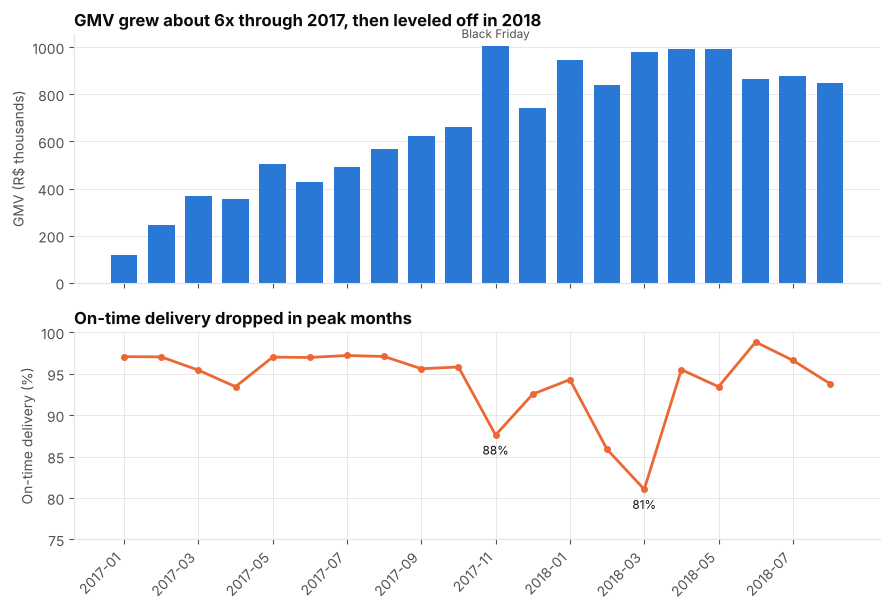

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(9, 6.2), sharex=True, gridspec_kw={"height_ratios": [1.2, 1]})
x = np.arange(len(kpi))
axes[0].bar(x, kpi.gmv / 1e3, color=BLUE, width=0.72)
axes[0].set_ylabel("GMV (R$ thousands)")
axes[0].set_title("GMV grew about 6x through 2017, then leveled off in 2018", loc="left")
nov = kpi.index[kpi.year_month == "2017-11"][0]
axes[0].annotate("Black Friday", (nov, kpi.gmv[nov] / 1e3), xytext=(0, 6), textcoords="offset points",
                 ha="center", fontsize=8.5, color=INK_2)
axes[0].grid(axis="x", visible=False)

axes[1].plot(x, kpi.on_time_rate * 100, color=ORANGE, lw=2, marker="o", ms=4)
for ym in ["2017-11", "2018-03"]:
    i = kpi.index[kpi.year_month == ym][0]
    axes[1].annotate(f"{kpi.on_time_rate[i]:.0%}", (i, kpi.on_time_rate[i] * 100), xytext=(0, -14),
                     textcoords="offset points", ha="center", fontsize=8.5, color=INK)
axes[1].set_ylabel("On-time delivery (%)")
axes[1].set_ylim(75, 100)
axes[1].set_title("On-time delivery dropped in peak months", loc="left")
axes[1].set_xticks(x[::2], kpi.year_month[::2], rotation=45, ha="right")
fig.tight_layout()
fig.savefig(f"{FIG}/monthly_gmv_on_time.png")
plt.show()

Two dips in on-time delivery stand out: **November 2017 (88%)**, the Black Friday volume spike, and **February–March 2018 (86% and 81%)**. Average review scores fell in exactly those months (3.93 in Nov 2017, 3.75 in March 2018, versus about 4.2 in normal months). That pattern is what the rest of the analysis tests.

## 3. SQL analyses

Each query is a file in `analysis/queries/` so it can be reviewed, reused, or scheduled.

### Q1. Growth: month over month, 3-month average and year to date
Window functions: `LAG` for growth, a sliding `AVG` for the moving average, and a `SUM` partitioned by year for YTD.

In [6]:
run_query("q01_monthly_growth").tail(8)

,year_month,valid_orders,gmv,mom_growth,gmv_3mo_avg,gmv_ytd
12,2018-01,7187,945456.0,0.274,897167.0,945456.0
13,2018-02,6625,837895.0,-0.114,841845.0,1783352.0
14,2018-03,7168,981051.0,0.171,921468.0,2764403.0
15,2018-04,6919,993593.0,0.013,937513.0,3757996.0
16,2018-05,6833,992872.0,-0.001,989172.0,4750868.0
17,2018-06,6145,863266.0,-0.131,949910.0,5614133.0
18,2018-07,6233,878044.0,0.017,911394.0,6492177.0
19,2018-08,6421,848860.0,-0.033,863390.0,7341037.0


### Q2. Which customer states get the worst delivery?

In [7]:
states = run_query("q02_delivery_by_state")
states

,customer_state,delivered_orders,on_time_rate,avg_delivery_days,avg_promised_days,avg_review,worst_rank
0,MA,720,0.826,21.5,30.4,3.82,1
1,CE,1281,0.863,21.3,31.4,3.94,2
2,BA,3254,0.878,19.3,29.4,3.91,3
3,RJ,12351,0.879,15.3,26.4,3.95,4
4,PA,946,0.888,23.8,37.2,3.89,5
5,ES,1996,0.893,15.8,25.6,4.05,6
6,PB,515,0.897,20.4,33.0,4.07,7
7,MS,700,0.903,15.6,26.0,4.16,8
8,PE,1592,0.903,18.4,31.0,4.07,9
9,SC,3547,0.918,14.9,25.8,4.12,10


Delivery is a geography problem. São Paulo (SP), where most sellers are, gets **95.5% on time in 8.8 days**. Northeastern states such as Maranhão (MA, 82.6%), Ceará (CE) and Bahia (BA) wait more than 19 days and are late far more often. Rio de Janeiro (RJ) stands out: it's the second-largest market by orders but only 87.9% on time.

### Q3. When an order is late, where was the time lost?

In [8]:
cause = run_query("q03_late_root_cause")
cause

,cause,late_orders,share_of_late,avg_days_late,avg_review
0,"Seller on time, carrier late",4708,0.722,10.9,2.26
1,Seller handed off late,1812,0.278,9.9,2.25
2,Unknown (no carrier date),1,0.000,6.0,5.00


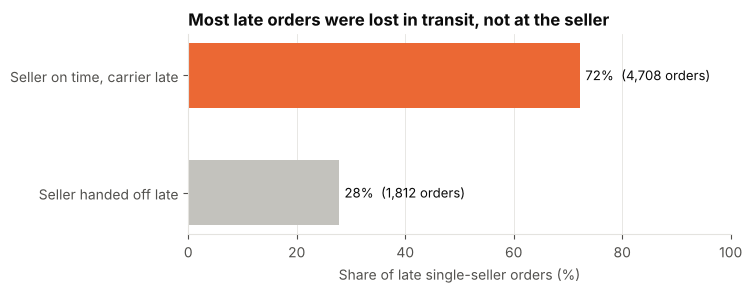

In [9]:
fig, ax = plt.subplots(figsize=(7, 2.6))
c = cause[cause.cause != "Unknown (no carrier date)"].iloc[::-1]
ax.barh(c.cause, c.share_of_late * 100, height=0.55,
        color=[ORANGE if "carrier" in name else GRAY for name in c.cause])
for y_, (v, n) in enumerate(zip(c.share_of_late, c.late_orders)):
    ax.text(v * 100 + 1, y_, f"{v:.0%}  ({n:,} orders)", va="center", color=INK, fontsize=9.5)
ax.set_xlim(0, 100)
ax.set_xlabel("Share of late single-seller orders (%)")
ax.grid(axis="y", visible=False)
ax.set_title("Most late orders were lost in transit, not at the seller", loc="left")
fig.savefig(f"{FIG}/late_root_cause.png")
plt.show()

**72% of late orders were handed to the carrier on time by the seller.** The delay happened in transit. So the main fix is on the logistics side (carrier performance and the delivery promise), not just seller discipline. The remaining 28% are a clear, measurable seller target.

### Q4. How concentrated is revenue across sellers?

In [10]:
run_query("q04_seller_concentration")

,gmv_decile,sellers,gmv,share_of_gmv,cumulative_share,avg_late_rate,avg_review
0,1,306,9108737.0,0.675,0.675,0.074,4.09
1,2,306,2039171.0,0.151,0.826,0.068,4.12
2,3,306,1032339.0,0.077,0.903,0.078,4.09
3,4,305,550417.0,0.041,0.943,0.078,4.13
4,5,305,327304.0,0.024,0.968,0.068,4.14
5,6,305,201878.0,0.015,0.983,0.072,4.02
6,7,305,117479.0,0.009,0.991,0.058,4.17
7,8,305,67216.0,0.005,0.996,0.084,4.06
8,9,305,36257.0,0.003,0.999,0.069,4.05
9,10,305,13603.0,0.001,1.000,0.062,3.92


**The top 10% of sellers generate 67.5% of GMV** and the top 30% generate 90%. Their late rates are no better than average, so a seller program focused on about 300 sellers would cover two-thirds of revenue.

### Q5. Do customers come back?

In [11]:
run_query("q05_repeat_purchase_cohorts")

,cohort,new_customers,repeat_90d,repeat_180d
0,2017-Q1,5152,0.0248,0.0307
1,2017-Q2,9087,0.0275,0.0353
2,2017-Q3,12208,0.0282,0.0361
3,2017-Q4,17261,0.0221,0.0273
4,2018-Q1,20441,0.0244,0.0298


Only **about 3% of new customers place a second order within 180 days**, in every cohort. Almost all revenue comes from first-time buyers, so each customer's first experience matters a great deal; section 4 tests whether a late first delivery makes it worse.

### Q6. How accurate is the delivery promise?

In [12]:
run_query("q06_promise_accuracy")

,year_month,delivered_orders,avg_promised_days,avg_actual_days,avg_buffer_days,on_time_rate
0,2017-01,750,39.5,12.6,26.9,0.971
1,2017-02,1653,31.8,13.2,18.7,0.970
2,2017-03,2546,24.7,13.0,11.8,0.954
3,2017-04,2303,27.3,14.9,12.4,0.934
4,2017-05,3545,24.3,11.3,13.0,0.970
5,2017-06,3135,24.0,12.0,12.0,0.970
6,2017-07,3872,23.3,11.6,11.7,0.972
7,2017-08,4193,23.5,11.1,12.3,0.971
8,2017-09,4150,22.4,11.9,10.6,0.956
9,2017-10,4478,23.0,11.9,11.2,0.958


The promised delivery date is usually padded by **about 11–12 days** over the actual delivery time. In the problem months the buffer shrank (7.4 days in Nov 2017, 5.7 in March 2018) because deliveries slowed while promises didn't adjust, and on-time rates fell. A promise that responds to current carrier speed would protect on-time delivery in peak months, without padding estimates the rest of the year.

## 4. Do late deliveries cause bad reviews?

Population: delivered orders with a review and at least one item (96,470 orders). An order is **late** if it arrived after the estimated date shown at purchase.

In [13]:
orders = sql("""
    SELECT f.*, c.state, d.year_month
    FROM fact_orders f
    JOIN dim_customer c ON c.customer_key = f.customer_key
    JOIN dim_date d     ON d.date_key = f.purchase_date_key
    WHERE f.is_delivered = 1 AND f.review_score IS NOT NULL AND f.item_count > 0
""")
print(f"{len(orders):,} orders, {orders.is_late.mean():.1%} late")

96,470 orders, 6.8% late


### Test 1: chi-squared test of independence
H0: the share of 1–2 star reviews is the same for late and on-time orders.

In [14]:
chi = chi_squared_2x2(orders.is_late, orders.is_low_review)
print(chi["table"].rename(index={0: "on time", 1: "late"}, columns={0: "3-5 stars", 1: "1-2 stars"}))
print(f"\n1-2 star share: on time {chi['rate_group0']:.1%} vs late {chi['rate_group1']:.1%}")
print(f"chi2 = {chi['chi2']:,.0f}, dof = {chi['dof']}, p < 0.001")

is_low_review  3-5 stars  1-2 stars
is_late                            
on time            81352       8584
late                2426       4108

1-2 star share: on time 9.5% vs late 62.9%
chi2 = 15,161, dof = 1, p < 0.001


### Test 2: Welch's t-test on the average score
Welch's version doesn't assume both groups have the same variance. Review scores are ordinal (1–5), so a Mann-Whitney U test is shown as a check that doesn't assume an interval scale.

In [15]:
from scipy.stats import mannwhitneyu
t = welch_t_test(orders.loc[orders.is_late == 0, "review_score"], orders.loc[orders.is_late == 1, "review_score"])
print(f"Average review: on time {t['mean_a']:.2f} vs late {t['mean_b']:.2f}")
print(f"Difference {t['diff']:.2f} stars, 95% CI [{t['ci_low']:.2f}, {t['ci_high']:.2f}], t = {t['t']:.1f}, p < 0.001")
mw = mannwhitneyu(orders.loc[orders.is_late == 1, "review_score"], orders.loc[orders.is_late == 0, "review_score"])
print("Mann-Whitney U: p < 0.001" if mw.pvalue < 0.001 else f"Mann-Whitney U: p = {mw.pvalue:.3f}")

Average review: on time 4.28 vs late 2.26
Difference -2.02 stars, 95% CI [-2.06, -1.99], t = -102.5, p < 0.001
Mann-Whitney U: p < 0.001


### Test 3: regression with controls

Late orders might differ in other ways (bigger orders, remote states, busy months) that also lower reviews. A regression holds those constant:

`review_score = b0 + b1 * is_late + order value + freight share + multi-item + multi-seller + first order + state + month`

The same model with `is_low_review` (1 if 1–2 stars) as the outcome gives the effect in percentage points. Standard errors are robust to unequal variance (HC1).

In [16]:
orders["log_order_value"] = np.log1p(orders.items_value)
orders["freight_share"] = orders.freight_value / (orders.items_value + orders.freight_value)
orders["multi_item"] = (orders.item_count > 1).astype(int)
orders["multi_seller"] = (orders.seller_count > 1).astype(int)
orders["first_order"] = (orders.customer_order_seq == 1).astype(int)
X = ["is_late", "log_order_value", "freight_share", "multi_item", "multi_seller", "first_order"]

stars = ols_robust(orders, "review_score", X, categorical=["state", "year_month"])
low = ols_robust(orders, "is_low_review", X, categorical=["state", "year_month"])
reg = pd.DataFrame({
    "effect on stars": stars.loc[X, "coef"],
    "95% CI (stars)": [f"[{a:.2f}, {b:.2f}]" for a, b in stars.loc[X, ["ci_low", "ci_high"]].to_numpy()],
    "effect on P(1-2 stars)": low.loc[X, "coef"],
    "p-value": stars.loc[X, "p_value"],
})
print(f"n = {stars.attrs['n']:,}, R² = {stars.attrs['r2']:.3f} (with state and month fixed effects)")
reg.style.format({"effect on stars": "{:+.2f}", "effect on P(1-2 stars)": "{:+.1%}",
                  "p-value": lambda p: "< 0.001" if p < 0.001 else f"{p:.3f}"})

n = 96,470, R² = 0.187 (with state and month fixed effects)


,effect on stars,95% CI (stars),effect on P(1-2 stars),p-value
is_late,-1.98,"[-2.02, -1.94]",+52.6%,< 0.001
log_order_value,-0.06,"[-0.07, -0.04]",+1.5%,< 0.001
freight_share,-0.45,"[-0.57, -0.34]",+8.6%,< 0.001
multi_item,-0.44,"[-0.48, -0.41]",+12.1%,< 0.001
multi_seller,-1.00,"[-1.10, -0.91]",+26.4%,< 0.001
first_order,-0.06,"[-0.10, -0.02]",+0.9%,0.003


With everything else held equal, **a late delivery lowers the review by about 2 stars and raises the chance of a 1–2 star review by about 53 percentage points**, almost the same as the raw comparison, so the effect isn't explained by order size, location or season.

A second finding: **orders split across several sellers score about 1 star lower** even when on time. Those orders usually arrive in separate parcels on different days.

### How fast do reviews fall as delays grow?

Among late orders, each extra day late lowers the review by 0.057 stars (95% CI 0.052 to 0.061)


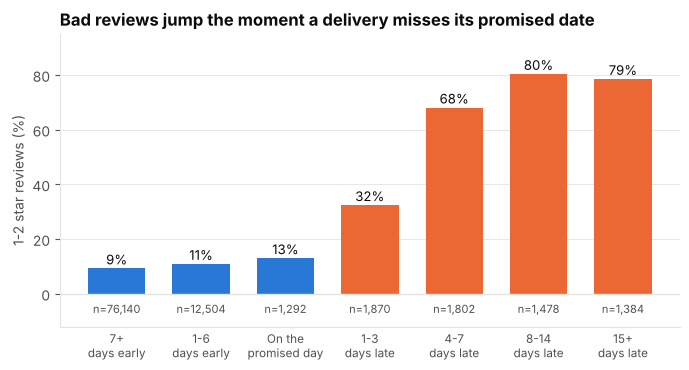

In [17]:
delay = sql("SELECT * FROM mart_delay_reviews ORDER BY bucket_order")
late_only = orders[orders.is_late == 1].assign(days_late_capped=lambda d: d.days_late.clip(upper=30))
slope = ols_robust(late_only, "review_score", ["days_late_capped"])
print(f"Among late orders, each extra day late lowers the review by {-slope.loc['days_late_capped', 'coef']:.3f} stars "
      f"(95% CI {-slope.loc['days_late_capped', 'ci_high']:.3f} to {-slope.loc['days_late_capped', 'ci_low']:.3f})")

fig, ax = plt.subplots(figsize=(8, 3.8))
colors = [BLUE if o <= 3 else ORANGE for o in delay.bucket_order]
labels = [b.replace(" days", "\ndays").replace("On the promised day", "On the\npromised day") for b in delay.delay_bucket]
ax.bar(labels, delay.low_review_rate * 100, color=colors, width=0.68)
for i_, (v, n) in enumerate(zip(delay.low_review_rate, delay.orders)):
    ax.text(i_, v * 100 + 1.5, f"{v:.0%}", ha="center", color=INK, fontsize=9.5)
    ax.text(i_, -7, f"n={n:,}", ha="center", color=INK_2, fontsize=8)
ax.set_ylim(-12, 95)
ax.axhline(0, color=GRID, lw=1)
ax.set_ylabel("1-2 star reviews (%)")
ax.tick_params(axis="x", labelsize=8.5, length=0)
ax.grid(axis="x", visible=False)
ax.set_title("Bad reviews jump the moment a delivery misses its promised date", loc="left")
fig.savefig(f"{FIG}/low_reviews_by_delay.png")
plt.show()

The jump happens **at the promise, not at a fixed number of days**: early orders get 9–11% bad reviews and orders arriving on the promised day 13%, but 1–3 days late jumps to 32% and 4–7 days late to 68%. Customers judge delivery against what they were promised.

### How much of the bad-review problem is lateness?

In [18]:
n_late = orders.is_late.sum()
excess = n_late * (chi["rate_group1"] - chi["rate_group0"])
total_low = orders.is_low_review.sum()
print(f"Late orders: {n_late:,}")
print(f"1-2 star reviews above the on-time rate: {excess:,.0f} of {total_low:,} total 1-2 star reviews ({excess / total_low:.0%})")

Late orders: 6,534
1-2 star reviews above the on-time rate: 3,484 of 12,692 total 1-2 star reviews (27%)


If late orders had the same bad-review rate as on-time ones, there would be about **3,500 fewer 1–2 star reviews: 27% of all of them**, from fixing just 6.8% of orders.

### Test 4: does a late *first* order cost repeat business?
New customers whose first order was delivered before March 2018 (so each has at least 6 months to come back):

In [19]:
first = sql("""
    SELECT f.is_late,
           EXISTS (SELECT 1 FROM fact_orders f2
                   WHERE f2.customer_key = f.customer_key AND f2.customer_order_seq = 2) AS came_back
    FROM fact_orders f
    WHERE f.customer_order_seq = 1 AND f.is_delivered = 1 AND f.purchase_ts < '2018-03-01'
""")
rep = chi_squared_2x2(first.is_late, first.came_back)
print(rep["table"].rename(index={0: "first order on time", 1: "first order late"}, columns={0: "no 2nd order", 1: "placed 2nd order"}))
print(f"\nRepeat rate: on time {rep['rate_group0']:.2%} vs late {rep['rate_group1']:.2%} "
      f"({rep['rate_group1'] / rep['rate_group0'] - 1:+.0%} relative), chi2 p = {rep['p_value']:.4f}")

came_back            no 2nd order  placed 2nd order
is_late                                            
first order on time         49652              2141
first order late             3555               112

Repeat rate: on time 4.13% vs late 3.05% (-26% relative), chi2 p = 0.0014


Customers whose first order arrived late were **26% less likely to buy again** (3.05% vs 4.13%, p = 0.001). The absolute numbers are small, because repeat buying is rare on this marketplace, but the direction is clear: late deliveries cost both ratings and future orders.

*Caveat:* this is observational data, so the regression controls for what's measured but can't rule out unmeasured differences (for example, specific products that are both slow to ship and disappointing). An A/B test, such as showing different promise dates, would be the way to confirm the effect.

## 5. What the warehouse design buys: query speed

`analysis/benchmark.py` answers the same questions three ways: from the raw source-shaped tables, from the star schema, and from the pre-built mart a dashboard reads. Times are the median of 7 runs on this machine.

In [20]:
bench = benchmark.run(DB)
b = pd.DataFrame(bench["questions"]).set_index("question")
b["star vs raw"] = (b["RAW"] / b["STAR"]).map("{:.1f}x faster".format)
b["mart vs raw"] = (b["RAW"] / b["MART"]).map("{:,.0f}x faster".format)
print(b[["RAW", "STAR", "MART"]].round(2).rename(columns=lambda c: c + " (ms)").join(b[["star vs raw", "mart vs raw"]]).to_string())
lk = bench["lookup"]
print(f"\nOne seller's order history: {lk['no_index_ms']:.1f} ms without an index -> {lk['with_index_ms']:.1f} ms with it "
      f"({lk['no_index_ms'] / lk['with_index_ms']:.0f}x)")
print("  plan without index:", lk["no_index_plan"])
print("  plan with index:   ", lk["with_index_plan"])

                                      RAW (ms)  STAR (ms)  MART (ms)  star vs raw     mart vs raw
question                                                                                         
Monthly GMV and on-time rate            326.42     145.90       0.02  2.2x faster  18,425x faster
Top 20 sellers by GMV with late rate    559.53     417.89       0.18  1.3x faster   3,130x faster

One seller's order history: 6.4 ms without an index -> 1.4 ms with it (4x)
  plan without index: SCAN i; SEARCH f USING INDEX sqlite_autoindex_fact_orders_1 (order_id=?)
  plan with index:    SEARCH i USING INDEX ix_items_seller (seller_key=?); SEARCH f USING INDEX sqlite_autoindex_fact_orders_1 (order_id=?)


- **Star schema vs raw tables:** typed columns, integer date keys and delivery measures computed once at load time make analytical queries a few times faster, and every query reuses the same tested definition of "late" instead of re-deriving it.
- **Marts for dashboards:** a dashboard tile reads a few dozen pre-aggregated rows in well under a millisecond, instead of re-scanning about 100k orders on every page load. On a cloud warehouse such as Redshift, that's also where the compute cost goes down.
- **Indexes on the fact table's foreign keys:** a seller lookup changes from a full table scan to an index search.

## 6. Recommendations

1. **Make the delivery promise dynamic, by region and season.** Bad reviews jump at the promised date, and on-time delivery collapsed when actual delivery times rose but promises didn't (Nov 2017, Feb–Mar 2018). Setting promises from recent carrier speed for each region would prevent most of these misses. Validate with an A/B test of promise dates, measuring both conversion and reviews.
2. **Work with carriers on the worst routes.** 72% of late orders were lost in transit. Start with the northeastern states (MA, CE, BA) and Rio de Janeiro, the largest market with below-average on-time delivery.
3. **Target seller handoff where it matters.** The 28% of late orders caused by late handoff are fixable with seller SLAs; the top 10% of sellers carry 67.5% of GMV.
4. **Protect first orders.** Repeat purchase is rare (about 3%), and a late first order cuts it by a quarter. Consider faster shipping or a more conservative promise for first-time buyers.
5. **Avoid split shipments.** Multi-seller orders score about 1 star lower even when on time; group them, or set expectations that they'll arrive in parts.

**Impact estimate:** bringing late orders to the on-time bad-review rate would remove about 3,500 of 12,700 1–2 star reviews (27%).